Homework Reflection 7

1. Create a linear regression model involving a confounder that is left out of the model.  Show whether the true correlation between $$X$$ and $$Y$$ is overestimated, underestimated, or neither.  Explain in words why this is the case for the given coefficients you have chosen.

In [1]:
import numpy as np
import statsmodels.api as sm

rng = np.random.default_rng(7)
n = 10_000

# W is the confounder: it causes both X and Y
W = rng.normal(0, 1, n)
X = 0.8 * W + rng.normal(0, 1, n)            # W raises X
Y = 2 * X + 3 * W + rng.normal(0, 1, n)      # true effect of X on Y = 2; W also raises Y

full    = sm.OLS(Y, sm.add_constant(np.column_stack([X, W]))).fit()   # includes W
omitted = sm.OLS(Y, sm.add_constant(X)).fit()                         # W left out

# Omitted-variable bias formula: b_X = true_b_X + b_W * Cov(X, W) / Var(X)
predicted = 2 + 3 * 0.8 / (0.8**2 + 1)

print(f"True effect of X on Y:          2.000")
print(f"Model with W (correct):         {full.params[1]:.3f}")
print(f"Model without W (confounded):   {omitted.params[1]:.3f}  <- overestimated")
print(f"Predicted by the OVB formula:   {predicted:.3f}")

# Same setup, but W now LOWERS Y -> the bias reverses
Y_neg = 2 * X - 3 * W + rng.normal(0, 1, n)
print(f"\nIf W lowers Y instead (-3 * W): {sm.OLS(Y_neg, sm.add_constant(X)).fit().params[1]:.3f}  <- underestimated")

True effect of X on Y:          2.000
Model with W (correct):         1.983
Model without W (confounded):   3.461  <- overestimated
Predicted by the OVB formula:   3.463

If W lowers Y instead (-3 * W): 0.543  <- underestimated


I simulated a confounder W that causes both the treatment and the outcome: X = 0.8·W + noise and Y = 2·X + 3·W + noise. The true effect of X on Y is 2. When W is included in the regression, the X coefficient is 1.98, which matches the truth. When W is left out, the X coefficient jumps to 3.46, so the effect is overestimated by about 73%.

The reason is that X and W move together (W raises X by 0.8 for each unit of W). Once W is removed from the model, the regression gives X credit for W's effect on Y, because high-X units also tend to have high W. The omitted-variable bias formula states this exactly: bias = (effect of W on Y) × Cov(X, W)/Var(X) = 3 × 0.8/1.64 ≈ 1.46, and 2 + 1.46 = 3.46, which matches the simulation.

The direction of the bias depends on the signs. Here both of W's effects are positive (W raises X and raises Y), so the bias is positive and X looks more effective than it is. If I change W's effect on Y to −3, the two signs disagree and the X coefficient drops to 0.54, an underestimate. Only when W is unrelated to X, or has no effect on Y, does leaving it out cause no bias.

---
2. Perform a linear regression analysis in which one of the coefficients is zero, e.g.

W = [noise]
X = [noise]
Y = 2 * X + [noise]

And compute the p-value of a coefficient - in this case, the coefficient of W.  
(This is the likelihood that the estimated coefficient would be as high or low as it is, given that the actual coefficient is zero.)
If the p-value is less than 0.05, this ordinarily means that we judge the coefficient to be nonzero (incorrectly, in this case.)
Run the analysis 1000 times and report the best (smallest) p-value.  
If the p-value is less than 0.05, does this mean the coefficient actually is nonzero?  What is the problem with repeating the analysis?

Smallest p-value for W:       0.00277  (W coef = +0.309)
Runs with p < 0.05:           46 / 1000  (4.6%, expected ~5%)
P(no p < 0.05 in 1000 runs) = 0.95^1000 = 5.3e-23  -> a 'significant' result is virtually guaranteed
Bonferroni threshold 0.05/1000 = 0.00005 -> runs still 'significant': 0


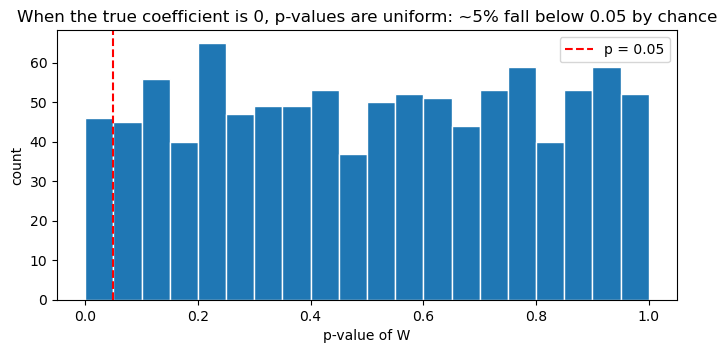

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

rng = np.random.default_rng(7)
n, n_runs = 100, 1000

p_values, w_coefs = [], []
for _ in range(n_runs):
    W = rng.normal(0, 1, n)                  # pure noise, no effect on Y
    X = rng.normal(0, 1, n)
    Y = 2 * X + rng.normal(0, 1, n)          # true coefficient of W is 0

    design = sm.add_constant(np.column_stack([W, X]))   # columns: const, W, X
    fit = sm.OLS(Y, design).fit()
    w_coefs.append(fit.params[1])
    p_values.append(fit.pvalues[1])
p_values, w_coefs = np.array(p_values), np.array(w_coefs)

best = p_values.argmin()
print(f"Smallest p-value for W:       {p_values[best]:.5f}  (W coef = {w_coefs[best]:+.3f})")
print(f"Runs with p < 0.05:           {(p_values < 0.05).sum()} / {n_runs}  "
      f"({(p_values < 0.05).mean():.1%}, expected ~5%)")
print(f"P(no p < 0.05 in {n_runs} runs) = 0.95^{n_runs} = {0.95**n_runs:.1e}  "
      f"-> a 'significant' result is virtually guaranteed")
print(f"Bonferroni threshold 0.05/{n_runs} = {0.05/n_runs:.5f} -> "
      f"runs still 'significant': {(p_values < 0.05/n_runs).sum()}")

plt.figure(figsize=(8, 3.5))
plt.hist(p_values, bins=20, range=(0, 1), edgecolor='white')
plt.axvline(0.05, color='red', ls='--', label='p = 0.05')
plt.xlabel('p-value of W'); plt.ylabel('count'); plt.legend()
plt.title('When the true coefficient is 0, p-values are uniform: ~5% fall below 0.05 by chance')
plt.show()

I simulated W and X as independent standard-normal noise, with Y = 2X + noise and n = 100. That means the true coefficient on W is exactly zero. I then fit the regression Y ~ W + X 1,000 times, each time on fresh data, and recorded the p-value for W's coefficient. The **smallest p-value was 0.0028**, with an estimated W coefficient of +0.31. Taken alone, that looks like strong evidence that W affects Y. In addition, 46 of the 1,000 runs (4.6%) had p < 0.05.

**No, a p-value below 0.05 does not mean the coefficient is actually nonzero.** We know the truth here: W has no effect on Y. A p-value is the probability of an estimate at least this extreme *assuming* the true coefficient is zero. So when the null hypothesis is true, p-values are uniformly distributed between 0 and 1, which is what the flat histogram shows. About 5% of runs will fall below 0.05 purely by chance; these are false positives (Type I errors). The 0.05 threshold controls the error rate for **one** pre-planned test, not for the best of many tests.

The problem with repeating the analysis is **multiple testing**, also called p-hacking. Each run has a 5% chance of a false positive. The chance that *none* of the 1,000 runs falls below 0.05 is 0.95^1000 ≈ 5 × 10⁻²³. So reporting the smallest p-value almost guarantees a "significant" result, even when there is no effect at all. The same thing happens in practice when someone tries many specifications, subgroups, or datasets and reports only the one that worked. A fix is to pre-register a single test, or to correct for the number of tests. For example, with a Bonferroni correction (0.05 / 1000 = 0.00005), none of the 1,000 runs is significant, which is the correct conclusion.